In [1]:
##% title Imports
import os
import xarray as xr

from popy.config import PROJECT_PATH_LOCAL as PATH

# plot cosine similarity between target subspaces
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# compute cosine similarity between target subspaces
from sklearn.metrics.pairwise import cosine_similarity

def plot_cosine_similarity_distribution(similarities, title=None):
    pass
    # plot the distribution of cosine similarity values for each pair of targets, color each pair separately
    fig, ax = plt.subplots(figsize=(4, 3))

    import numpy as np
    bins = np.arange(-1, 1.1, 0.1)

    # stacked histogram for the 3 pairs
    ax.hist(
        similarities['1-2'],
        bins=bins,
        color='blue',
        alpha=0.2,
        zorder=2
    )
    ax.hist(
        similarities['1-3'],
        bins=bins,
        color='orange',
        alpha=0.2,
        zorder=2
    )
    ax.hist(
        similarities['2-3'],
        bins=bins,
        color='green',
        alpha=0.2,
        zorder=2
    )

    ax.axvline(x=0, color='grey', linestyle='--')
    ax.set_xlabel('Cosine Similarity')
    ax.set_ylabel('Count')

    ax_ = ax.twinx()  # create a second y-axis for the KDE plot
    # in black plot the concatenated KDE distribution of all pairs
    sns.kdeplot(similarities['1-2'] + similarities['1-3'] + similarities['2-3'], label='All Pairs', color='black', ax=ax_, linewidth=2, zorder=10)

    sns.kdeplot(similarities['1-2'], color='blue', ax=ax_, alpha=0.5, zorder=2, label='1-2')
    sns.kdeplot(similarities['1-3'], color='orange', ax=ax_, alpha=0.5, zorder=3, label='1-3')
    sns.kdeplot(similarities['2-3'], color='green', ax=ax_, alpha=0.5, zorder=4, label='2-3')
    ax_.set_ylabel('Density')

    if title:
        plt.title(title)
    else:
        plt.title('Distribution of Cosine Similarity between Target Subspaces')

    # make legend for ax_
    ax.spines['top'].set_visible(False)
    ax_.spines['top'].set_visible(False)
    ax_.legend(loc='upper left', bbox_to_anchor=(1.2, 1))
    return fig, axes

def plot_cosine_similarity_distribution(similarities, title=None):
    # plot the distribution of cosine similarity values for each pair of targets, color each pair separately
    fig, ax = plt.subplots(figsize=(4, 3))

    import numpy as np
    bins = np.arange(-1, 1.1, 0.1)

    # in black plot the concatenated KDE distribution of all pairs
    sns.kdeplot(
        (similarities['1a-1b'] + 
         similarities['2a-2b'] + 
         similarities['3a-3b']),
         label='Same target', color='tab:blue', ax=ax, linewidth=2, zorder=10)

    sns.kdeplot(
        (similarities['1a-2a'] + 
         similarities['1a-3a'] + 
         similarities['2a-3a'] +
         similarities['1b-2b'] +
         similarities['1b-3b'] +
         similarities['2b-3b'] +
         similarities['1a-2b'] +
         similarities['1a-3b'] +
         similarities['2a-3b'] +
         similarities['1b-2a'] +
         similarities['1b-3a'] +
         similarities['2b-3a']),
         label='Different targets', color='tab:orange', ax=ax, linewidth=2, zorder=10)

    ax.axvline(x=0, color='grey', linestyle='--')
    ax.set_xlabel('Cosine Similarity')
    '''sns.kdeplot(similarities['1-2'], color='blue', ax=ax, alpha=0.5, zorder=2, label='1-2')
    sns.kdeplot(similarities['1-3'], color='orange', ax=ax, alpha=0.5, zorder=3, label='1-3')
    sns.kdeplot(similarities['2-3'], color='green', ax=ax, alpha=0.5, zorder=4, label='2-3')'''
    ax.set_ylabel('Density')

    ax_ = ax.twinx()  # create a second y-axis for the histogram plot
    bins = np.arange(-1, 1.1, 0.1)
    
    # stacked histogram for the 3 pairs
    ax_.hist(
        (similarities['1a-1b'] + similarities['2a-2b'] + similarities['3a-3b']),
        bins=bins,
        color='tab:blue',
        alpha=0.2,
        zorder=3
    )
    ax_.hist((
        similarities['1a-2a'] + similarities['1a-3a'] + similarities['2a-3a'] +
        similarities['1b-2b'] + similarities['1b-3b'] + similarities['2b-3b'] +
        similarities['1a-2b'] + similarities['1a-3b'] + similarities['2a-3b'] +
        similarities['1b-2a'] + similarities['1b-3a'] + similarities['2b-3a']),
        bins=bins,
        color='tab:orange',
        alpha=0.2,
        zorder=2
    )
    ax_.set_ylabel('Count')

    if title:
        plt.title(title)
    else:
        plt.title('Distribution of Cosine Similarity between Target Subspaces')

    ax.set_xlim(-1.1, 1.1)
    ax_.set_xlim(-1.1, 1.1)
    
    # make legend for ax_
    ax.spines['top'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.legend(loc='upper left', bbox_to_anchor=(1.2, 1))
    return fig, ax

/home/uzsombi/.config/matplotlib is not a writable directory
Matplotlib created a temporary cache directory at /tmp/matplotlib-bs4wpt0v because there was an issue with the default path (/home/uzsombi/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


In [2]:
base_path = os.path.join(PATH, 'notebooks', 'population_decoding', 'figs')

In [3]:
floc = os.path.join(PATH, 'notebooks', 'population_decoding', 'neural_value', 'results', 'across_target_weights_split_before_fb')
fname = 'weights.nc'

# load xarray dataset of weights, make a copy, close
ds = xr.open_dataset(os.path.join(floc, fname))

Processing subregion: MCC
Processing subregion: dLPFC
Processing subregion: vLPFC


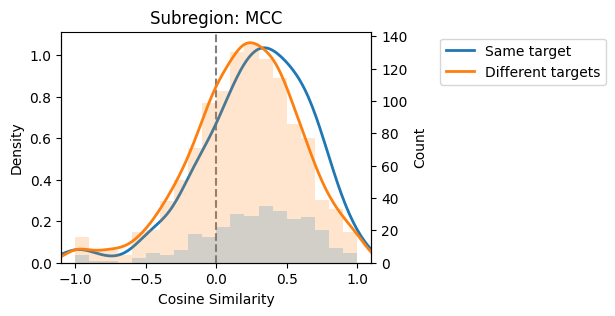

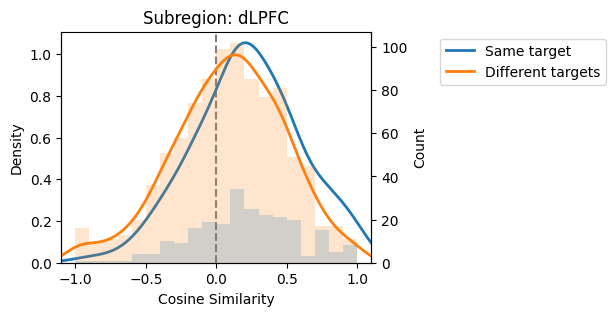

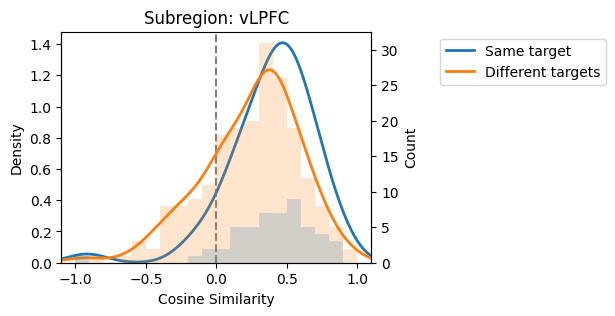

In [4]:

for subregion in np.unique(ds.subregion.values):
    print(f'Processing subregion: {subregion}')
    ds_sub = ds.sel(unit=ds.subregion==subregion)

    # list monkey, session combinations
    monkey_list = [str(m) for m in ds_sub.monkey.values]
    session_list = [str(s) for s in ds_sub.session.values]

    # make unique tuples
    combinations = set(zip(monkey_list, session_list))

    similarities = {'1a-1b': [], '2a-2b': [], '3a-3b': [], # compare first half with second half
                    
                    '1a-2a': [], '1a-3a': [], '2a-3a': [], # compare within split (first-first)
                    '1b-2b': [], '1b-3b': [], '2b-3b': [], # compare within split (second-second)

                    '1a-2b': [], '1a-3b': [], '2a-3b': [], # compare across split (first-second)
                    '1b-2a': [], '1b-3a': [], '2b-3a': []} # compare across split (second-first)

    for monkey, session in combinations:
        # get subsession
        ds_temp = ds_sub.sel(unit=(ds_sub.monkey==monkey) & (ds_sub.session==session))

        # extract mean weights per target
        mean_weights = ds_temp.mean(dim='time')

        target_subspaces = mean_weights.__xarray_dataarray_variable__.values  # shape: (n_targets, n_features)
        # flatten: from AxBxC to (A*B)xC
        target_subspaces = np.array([target_subspaces[0, 0], target_subspaces[1, 0], target_subspaces[2, 0], 
                                     target_subspaces[0, 1], target_subspaces[1, 1], target_subspaces[2, 1]])
        cosine_sim_matrix = cosine_similarity(target_subspaces)

        # save cosine similarity values for each pair of targets
        similarities['1a-1b'].append(cosine_sim_matrix[0, 3])
        similarities['2a-2b'].append(cosine_sim_matrix[1, 4])
        similarities['3a-3b'].append(cosine_sim_matrix[2, 5])

        similarities['1a-2a'].append(cosine_sim_matrix[0, 1])
        similarities['1a-3a'].append(cosine_sim_matrix[0, 2])
        similarities['2a-3a'].append(cosine_sim_matrix[1, 2])

        similarities['1b-2b'].append(cosine_sim_matrix[3, 4])
        similarities['1b-3b'].append(cosine_sim_matrix[3, 5])
        similarities['2b-3b'].append(cosine_sim_matrix[4, 5])

        similarities['1a-2b'].append(cosine_sim_matrix[0, 4])
        similarities['1a-3b'].append(cosine_sim_matrix[0, 5])
        similarities['2a-3b'].append(cosine_sim_matrix[1, 5])

        similarities['1b-2a'].append(cosine_sim_matrix[3, 1])
        similarities['1b-3a'].append(cosine_sim_matrix[3, 2])
        similarities['2b-3a'].append(cosine_sim_matrix[4, 2])

    fig, axes = plot_cosine_similarity_distribution(similarities, title=f'Subregion: {subregion}')
    # save figure
    fig.savefig(os.path.join(base_path, f'cos_sim_split{subregion}.png'), bbox_inches='tight', dpi=300)

In [ ]:

for subregion in np.unique(ds.subregion.values):
    print(f'Processing subregion: {subregion}')
    ds_sub = ds.sel(unit=ds.subregion==subregion)

    # list monkey, session combinations
    monkey_list = [str(m) for m in ds_sub.monkey.values]
    session_list = [str(s) for s in ds_sub.session.values]

    # make unique tuples
    combinations = set(zip(monkey_list, session_list))

    similarities = {'1a-1b': [], '2a-2b': [], '3a-3b': [], # compare first half with second half
                    
                    '1a-2a': [], '1a-3a': [], '2a-3a': [], # compare within split (first-first)
                    '1b-2b': [], '1b-3b': [], '2b-3b': [], # compare within split (second-second)

                    '1a-2b': [], '1a-3b': [], '2a-3b': [], # compare across split (first-second)
                    '1b-2a': [], '1b-3a': [], '2b-3a': []} # compare across split (second-first)

    for monkey, session in combinations:
        # get subsession
        ds_temp = ds_sub.sel(unit=(ds_sub.monkey==monkey) & (ds_sub.session==session))

        # extract mean weights per target
        mean_weights = ds_temp.mean(dim='time')

        target_subspaces = mean_weights.__xarray_dataarray_variable__.values  # shape: (n_targets, n_features)
        # flatten: from AxBxC to (A*B)xC
        target_subspaces = np.array([target_subspaces[0, 0], target_subspaces[1, 0], target_subspaces[2, 0], 
                                     target_subspaces[0, 1], target_subspaces[1, 1], target_subspaces[2, 1]])
        cosine_sim_matrix = cosine_similarity(target_subspaces)

        # save cosine similarity values for each pair of targets
        similarities['1a-1b'].append(cosine_sim_matrix[0, 3])
        similarities['2a-2b'].append(cosine_sim_matrix[1, 4])
        similarities['3a-3b'].append(cosine_sim_matrix[2, 5])

        similarities['1a-2a'].append(cosine_sim_matrix[0, 1])
        similarities['1a-3a'].append(cosine_sim_matrix[0, 2])
        similarities['2a-3a'].append(cosine_sim_matrix[1, 2])

        similarities['1b-2b'].append(cosine_sim_matrix[3, 4])
        similarities['1b-3b'].append(cosine_sim_matrix[3, 5])
        similarities['2b-3b'].append(cosine_sim_matrix[4, 5])

        similarities['1a-2b'].append(cosine_sim_matrix[0, 4])
        similarities['1a-3b'].append(cosine_sim_matrix[0, 5])
        similarities['2a-3b'].append(cosine_sim_matrix[1, 5])

        similarities['1b-2a'].append(cosine_sim_matrix[3, 1])
        similarities['1b-3a'].append(cosine_sim_matrix[3, 2])
        similarities['2b-3a'].append(cosine_sim_matrix[4, 2])

    fig, axes = plot_cosine_similarity_distribution(similarities, title=f'Subregion: {subregion}')
    # save figure
    fig.savefig(os.path.join(base_path, f'cos_sim_split{subregion}.png'), bbox_inches='tight', dpi=300)

In [5]:

for subregion in np.unique(ds.subregion.values):
    print(f'Processing subregion: {subregion}')
    ds_sub = ds.sel(unit=ds.subregion==subregion)

    # list monkey, session combinations
    monkey_list = [str(m) for m in ds_sub.monkey.values]
    session_list = [str(s) for s in ds_sub.session.values]

    # make unique tuples
    combinations = set(zip(monkey_list, session_list))

    similarities = {'1-2': [], '1-3': [], '2-3': []}

    for monkey, session in combinations:
        print(f'Processing monkey: {monkey}, session: {session}')
        # get subsession
        ds_temp = ds_sub.sel(unit=(ds_sub.monkey==monkey) & (ds_sub.session==session))

        for t in ds_temp.time.values:
            # extract mean weights per target
            temp_weights = ds_temp.sel(time=t)

            target_subspaces = temp_weights.__xarray_dataarray_variable__.values  # shape: (n_targets, n_features)
            cosine_sim_matrix = cosine_similarity(target_subspaces)

            # save cosine similarity values for each pair of targets
            similarities['1-2'].append(cosine_sim_matrix[0, 1])
            similarities['1-3'].append(cosine_sim_matrix[0, 2])
            similarities['2-3'].append(cosine_sim_matrix[1, 2])

    fig, axes = plot_cosine_similarity_distribution(similarities, title=f'Subregion: {subregion}')
    # save figure
    fig.savefig(os.path.join(base_path, f'cos_sim_time_{subregion}.png'), bbox_inches='tight', dpi=300)

Processing subregion: MCC
Processing monkey: ka, session: 050820


ValueError: Found array with dim 3. check_pairwise_arrays expected <= 2.